# Step 12 — Do wind events come before sudden changes?

Live, the model loses to the blend rule on a few days when chlorophyll jumps or drops sharply overnight
(step 11). Step 05 found that daily wind, as an input, adds little on average. This step asks a narrower
question before any new model is built: **do days of strong wind come before the sudden changes, and is that
where the model's extra error falls?** It also tests a cheap alternative: hedging the model towards the blend.

**Data.** Archive (MY) chlorophyll and ASCAT wind, 2019–2025 (wind starts in 2019). Wind is used as a forecast
would have it: only days before the issue day (one day late, as in step 04). Daily wind is the average over the
modelled area of both satellite passes; a day needs at least 10% of the area observed.

**Definitions, fixed before looking at results.**
* A **sudden-change day** is an issue day whose average next-day change, |log10 target − log10 latest|, is in the
  top 10% for its season. Judging within season stops winter, when everything changes more, dominating.
* **Wind measures** at the issue day: yesterday's wind; the strongest day in the past 3; the past 3 days'
  mixing energy (mean of speed³); and the rise of yesterday's wind over the week before.
* **Wind classes**: within each season, days are split into five equal groups by wind (1 = calmest, 5 = windiest).

**Decision rule, fixed in advance.** Wind is worth a modelling step (step 13) if, for the strongest-in-3-days
measure at +1 day, sudden-change days are **at least 1.5 times as common in the windiest fifth as in the calmest
fifth**, and the 95% range of that ratio (resampling whole weeks) lies **above 1**. Otherwise wind is not the
answer to the sudden changes. The model's error by wind class and the hedge are reported for information; the
hedge weight (half and half) is fixed, not tuned.

The model was trained on issue days up to 2024: wind and chlorophyll alone (question 1) do not involve it, but
its scores in 2019–2024 (question 2) are in-sample, so 2025 is shown separately.

In [1]:
import json
from datetime import datetime, timezone

import joblib
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import spearmanr

from chlforecast import archive, config, forecast, scoring
from chlforecast import features as F

YEARS = list(range(2019, 2026))
SUDDEN_TOP_SHARE = 0.10           # top 10% of days in each season
MIN_WIND_SHARE = 0.10             # a wind day needs 10% of the area observed
MIN_PIXELS = 500                  # an issue day needs this many scored pixels
N_CLASSES = 5
RULE_RATIO, PRIMARY = 1.5, "Strongest of past 3 days"
HEDGE_WEIGHT = 0.5                # share of the model in the hedge (log scale); fixed, not tuned
SEASONS = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
           6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}

bundle = joblib.load(config.MODEL_PATH)
mask = bundle["model_mask"].values == 1
latitude = bundle["model_mask"].latitude.values
longitude = bundle["model_mask"].longitude.values
horizons = [int(h) for h in bundle["forecast_horizons_days"]]
min_chl = bundle["preprocessing"]["min_plausible_chl_mg_m3"]
trained_until = pd.Timestamp(bundle["training_issue_date_range"][1])

observations = xr.open_dataset(config.PROCESSED / "malta_daily_observations.nc")
GRID = ("time", "latitude", "longitude")
print(f"Model {config.MODEL_PATH.name}, trained on issue days up to {trained_until:%Y-%m-%d}; years {YEARS[0]}–{YEARS[-1]}")

Model chl_forecast_step09.joblib, trained on issue days up to 2024-12-24; years 2019–2025


## Daily wind over the area

In [2]:
block = observations.sel(time=slice(f"{YEARS[0] - 1}-12-01", f"{YEARS[-1]}-12-31"))
wind_dates = pd.DatetimeIndex(block.time.values)
speeds = np.concatenate([block["wind_speed_asc"].transpose(*GRID).values[:, mask],
                         block["wind_speed_des"].transpose(*GRID).values[:, mask]], axis=1)
observed = np.isfinite(speeds).sum(axis=1)
enough = observed >= MIN_WIND_SHARE * 2 * mask.sum()
with np.errstate(invalid="ignore"):
    daily_speed = pd.Series(np.where(enough, np.nanmean(speeds, axis=1), np.nan), index=wind_dates)
    daily_cube = pd.Series(np.where(enough, np.nanmean(speeds ** 3, axis=1), np.nan), index=wind_dates)
del speeds

# Measures on each issue day, from wind measured up to the day before (one day late, as in step 04).
lag = config.WIND_LAG_DAYS
past = daily_speed.shift(lag)
wind = pd.DataFrame({
    "Yesterday": past,
    "Strongest of past 3 days": past.rolling(3, min_periods=2).max(),
    "Mixing energy, past 3 days": daily_cube.shift(lag).rolling(3, min_periods=2).mean(),
    "Rise over the week before": past - daily_speed.shift(lag + 1).rolling(7, min_periods=4).mean(),
})
wind.index.name = "Issue day"

display(pd.Series({
    "Days with wind over the area": f"{int(enough.sum()):,} of {len(enough):,} ({100 * enough.mean():.0f}%)",
    "Typical daily wind (m/s)": f"{np.nanmedian(daily_speed):.1f}",
    "Windiest 10% of days above (m/s)": f"{np.nanpercentile(daily_speed, 90):.1f}",
}).to_frame("Value"))

/var/folders/7p/5gfllgzs6033lyk2410ng6xm0000gn/T/ipykernel_85284/3337183.py:8: RuntimeWarning: Mean of empty slice
  daily_speed = pd.Series(np.where(enough, np.nanmean(speeds, axis=1), np.nan), index=wind_dates)
/var/folders/7p/5gfllgzs6033lyk2410ng6xm0000gn/T/ipykernel_85284/3337183.py:9: RuntimeWarning: Mean of empty slice
  daily_cube = pd.Series(np.where(enough, np.nanmean(speeds ** 3, axis=1), np.nan), index=wind_dates)


,Value
Days with wind over the area,"1,833 of 2,588 (71%)"
Typical daily wind (m/s),5.6
Windiest 10% of days above (m/s),10.4


## Forecasts and their errors, day by day

The model and the blend rule are run on the archive with the shared recipe, scored with step 07's rules. For each
issue day this keeps the number of scored pixels, the average next-day change, and the summed squared log errors
of the model, the blend and the hedge, enough to pool any group of days afterwards. This cell takes a few minutes.

In [3]:
def year_block(year):
    """One year of issue days, with 40 days of history before and 7 days of targets after."""
    b = observations.sel(time=slice(pd.Timestamp(f"{year}-01-01") - pd.Timedelta(days=40),
                                    pd.Timestamp(f"{year}-12-31") + pd.Timedelta(days=max(horizons))))
    return {"chl": F.quality_control(b["chl"].transpose(*GRID).values, minimum=min_chl),
            "sst": b["sst_c"].transpose(*GRID).values, "dates": pd.DatetimeIndex(b.time.values)}


def build_inputs(b):
    inputs = F.model_inputs(b["chl"], b["sst"], b["dates"], mask, bundle["monthly_log_climatology"].values,
                            bundle["monthly_sst_climatology"].values, bundle["coast_distance_km"].values,
                            latitude, longitude)
    return {name: np.broadcast_to(v, b["chl"].shape) for name, v in inputs.items()}


def day_errors(b, inputs, issue_index, h):
    """Per issue day: scored pixels, mean |log change|, summed squared log errors per method."""
    dates = b["dates"]
    issue_index = issue_index[issue_index + h < len(dates)]      # the target must be in the data
    model = forecast.model_forecast(bundle, inputs, dates, h)[issue_index]
    blend = forecast.blend_forecast(bundle, inputs, dates, h)[issue_index]
    latest = inputs["chl_latest"][issue_index]
    target = b["chl"][issue_index + h]
    scored = (np.isfinite(target) & (target > 0) & mask[None] & np.isfinite(latest) & np.isfinite(model))
    with np.errstate(divide="ignore", invalid="ignore"):
        lt, lm, lb, lp = (np.log10(x) for x in (target, model, blend, latest))
    lh = HEDGE_WEIGHT * lm + (1 - HEDGE_WEIGHT) * lb
    def per_day(x):
        return np.where(scored, x, 0).sum(axis=(1, 2))
    n = scored.sum(axis=(1, 2))
    return pd.DataFrame({
        "Issue day": dates[issue_index], "Horizon": h, "Pixels": n,
        "Mean abs change": np.where(n > 0, per_day(np.abs(lt - lp)) / np.maximum(n, 1), np.nan),
        "Mean change": np.where(n > 0, per_day(lt - lp) / np.maximum(n, 1), np.nan),
        "SSE model": per_day((lm - lt) ** 2), "SSE blend": per_day((lb - lt) ** 2), "SSE hedge": per_day((lh - lt) ** 2),
        "SSE no change": per_day((lp - lt) ** 2),
    })


frames = []
for year in YEARS:
    b = year_block(year)
    inputs = build_inputs(b)
    issue_index = np.flatnonzero(b["dates"].year == year)
    for h in (horizons if year == YEARS[-1] else [1]):     # all lead times only for the unseen year
        frames.append(day_errors(b, inputs, issue_index, h))
    del b, inputs
    print(f"{year} done", flush=True)
days = pd.concat(frames, ignore_index=True)
days["Season"] = days["Issue day"].dt.month.map(SEASONS)
days["Year"] = days["Issue day"].dt.year
days["In training"] = days["Issue day"] + pd.to_timedelta(days["Horizon"], unit="D") <= trained_until
days = days.join(wind, on="Issue day")

# Sudden-change days, within season, at +1 day.
d1 = days[(days["Horizon"] == 1) & (days["Pixels"] >= MIN_PIXELS)].copy()
d1["Sudden"] = d1.groupby("Season")["Mean abs change"].transform(lambda s: s >= s.quantile(1 - SUDDEN_TOP_SHARE))
print(f"+1 day: {len(d1):,} issue days with at least {MIN_PIXELS} scored pixels; "
      f"{int(d1['Sudden'].sum())} sudden-change days "
      f"(next-day change above about {100 * (10 ** d1.loc[d1['Sudden'], 'Mean abs change'].min() - 1):.0f}%)")

2019 done
2020 done
2021 done
2022 done
2023 done
2024 done
2025 done
+1 day: 2,134 issue days with at least 500 scored pixels; 216 sudden-change days (next-day change above about 23%)


## 1. Does wind come before sudden changes?

Within each season, how strongly each wind measure goes with the next-day change (rank correlation of the two,
each ranked within its season), and how often sudden-change days fall in the windiest and calmest fifths.

,Issue days,Correlation with next-day change,95% low,95% high,"Sudden days, windiest fifth (%)","Sudden days, calmest fifth (%)",Ratio,Ratio 95% low,Ratio 95% high
Wind measure,,,,,,,,,
Yesterday,"1,522",+0.21,+0.15,+0.26,16.0,4.9,3.27,1.89,6.25
Strongest of past 3 days,"1,884",+0.21,+0.15,+0.27,17.2,9.0,1.92,1.26,3.01
"Mixing energy, past 3 days","1,884",+0.22,+0.16,+0.28,17.8,7.4,2.41,1.54,3.89
Rise over the week before,"1,507",+0.08,+0.02,+0.13,14.2,9.2,1.54,0.97,2.55


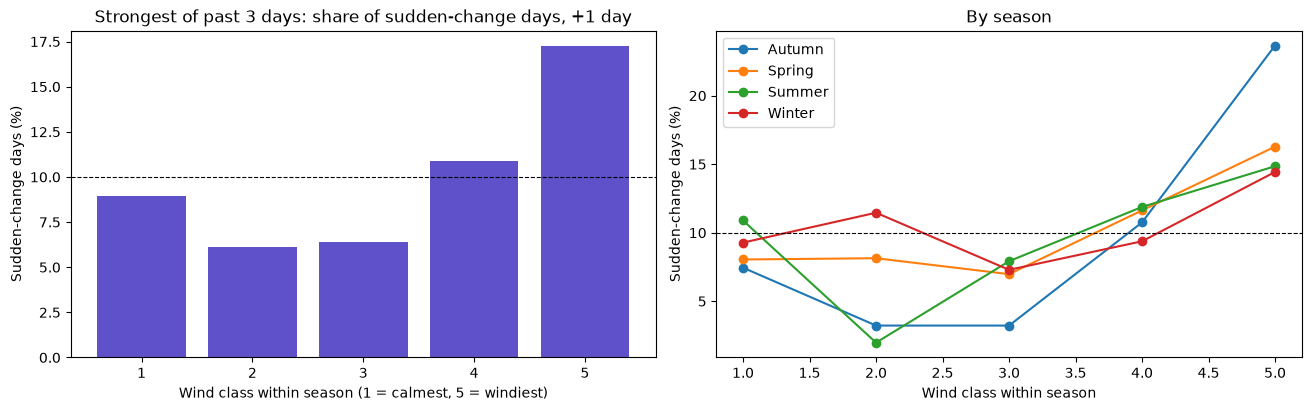

,Issue days,Sudden days (%),Mean next-day change (%),"Wind (m/s), median"
Wind class,,,,
1,379,9.0,20.2,4.0
2,376,6.1,20.9,6.0
3,376,6.4,20.4,7.7
4,376,10.9,22.3,9.4
5,377,17.2,25.6,11.7


In [4]:
def season_rank(frame, column):
    return frame.groupby("Season")[column].rank(pct=True)


def week_bootstrap(frame, statistic, n_boot=1000, seed=0):
    """95% range of a statistic, resampling whole weeks (neighbouring days are alike)."""
    weeks = ((frame["Issue day"] - frame["Issue day"].min()).dt.days // 7).to_numpy()
    groups = [np.flatnonzero(weeks == w) for w in np.unique(weeks)]
    rng = np.random.default_rng(seed)
    values = []
    for _ in range(n_boot):
        pick = np.concatenate([groups[k] for k in rng.integers(0, len(groups), len(groups))])
        values.append(statistic(frame.iloc[pick]))
    return np.nanpercentile(values, [2.5, 97.5])


def wind_classes(frame, measure):
    out = frame.dropna(subset=[measure]).copy()
    out["Wind class"] = out.groupby("Season")[measure].transform(
        lambda s: pd.qcut(s.rank(method="first"), N_CLASSES, labels=False) + 1)
    return out


def sudden_ratio(frame):
    top = frame.loc[frame["Wind class"] == N_CLASSES, "Sudden"].mean()
    bottom = frame.loc[frame["Wind class"] == 1, "Sudden"].mean()
    return top / bottom if bottom > 0 else np.nan


rows = []
for measure in wind.columns:
    f = wind_classes(d1, measure)
    rho = spearmanr(season_rank(f, measure), season_rank(f, "Mean abs change")).statistic
    rho_low, rho_high = week_bootstrap(f, lambda x: spearmanr(season_rank(x, measure), season_rank(x, "Mean abs change")).statistic)
    ratio = sudden_ratio(f)
    ratio_low, ratio_high = week_bootstrap(f, sudden_ratio)
    rows.append({"Wind measure": measure, "Issue days": len(f),
                 "Correlation with next-day change": rho, "95% low": rho_low, "95% high": rho_high,
                 "Sudden days, windiest fifth (%)": 100 * f.loc[f["Wind class"] == N_CLASSES, "Sudden"].mean(),
                 "Sudden days, calmest fifth (%)": 100 * f.loc[f["Wind class"] == 1, "Sudden"].mean(),
                 "Ratio": ratio, "Ratio 95% low": ratio_low, "Ratio 95% high": ratio_high})
wind_vs_change = pd.DataFrame(rows).set_index("Wind measure")
display(wind_vs_change.style.format({"Issue days": "{:,.0f}", "Correlation with next-day change": "{:+.2f}",
                                     "95% low": "{:+.2f}", "95% high": "{:+.2f}",
                                     "Sudden days, windiest fifth (%)": "{:.1f}", "Sudden days, calmest fifth (%)": "{:.1f}",
                                     "Ratio": "{:.2f}", "Ratio 95% low": "{:.2f}", "Ratio 95% high": "{:.2f}"}))

primary = wind_classes(d1, PRIMARY)
by_class = primary.groupby("Wind class").agg(**{
    "Issue days": ("Sudden", "size"), "Sudden days (%)": ("Sudden", lambda s: 100 * s.mean()),
    "Mean next-day change (%)": ("Mean abs change", lambda s: 100 * (10 ** s.mean() - 1)),
    "Wind (m/s), median": (PRIMARY, "median")})
by_season = primary.pivot_table(index="Season", columns="Wind class", values="Sudden", aggfunc="mean") * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
axes[0].bar(by_class.index, by_class["Sudden days (%)"], color="#5f51c9")
axes[0].axhline(100 * SUDDEN_TOP_SHARE, color="black", lw=0.8, ls="--")
axes[0].set(xlabel="Wind class within season (1 = calmest, 5 = windiest)", ylabel="Sudden-change days (%)",
            title=f"{PRIMARY}: share of sudden-change days, +1 day")
for season in by_season.index:
    axes[1].plot(by_season.columns, by_season.loc[season], marker="o", label=season)
axes[1].axhline(100 * SUDDEN_TOP_SHARE, color="black", lw=0.8, ls="--")
axes[1].set(xlabel="Wind class within season", ylabel="Sudden-change days (%)", title="By season")
axes[1].legend()
plt.show()
display(by_class.style.format({"Issue days": "{:,.0f}", "Sudden days (%)": "{:.1f}",
                               "Mean next-day change (%)": "{:.1f}", "Wind (m/s), median": "{:.1f}"}))

### 1b. Up or down?

Added after the first run, as a description (it is not part of the decision rule): a forecast of the amount can only use
wind if wind also says **which way** chlorophyll will move. Within season, the signed next-day change by wind class.

In [5]:
direction = primary.groupby("Wind class").agg(**{
    "Issue days": ("Mean change", "size"),
    "Average change (%)": ("Mean change", lambda s: 100 * (10 ** s.mean() - 1)),
    "Days rising (%)": ("Mean change", lambda s: 100 * (s > 0).mean()),
    "Sudden days rising (%)": ("Mean change", lambda s: 100 * (s[primary.loc[s.index, "Sudden"]] > 0).mean()),
})
display(direction.style.format({"Issue days": "{:,.0f}", "Average change (%)": "{:+.1f}",
                                "Days rising (%)": "{:.0f}", "Sudden days rising (%)": "{:.0f}"}))
direction_rho = spearmanr(season_rank(primary, PRIMARY), primary["Mean change"]).statistic
print(f"Rank correlation of wind (within season) with the signed change: {direction_rho:+.2f} "
      f"(with the size of the change: {wind_vs_change.loc[PRIMARY, 'Correlation with next-day change']:+.2f})")

,Issue days,Average change (%),Days rising (%),Sudden days rising (%)
Wind class,,,,
1,379,-1.3,47,50
2,376,+0.3,48,65
3,376,-0.7,45,46
4,376,+1.3,52,63
5,377,+1.1,47,60


Rank correlation of wind (within season) with the signed change: +0.03 (with the size of the change: +0.21)


## 2. Is that where the model's extra error falls?

The model's gain over the blend rule by wind class, and on sudden-change days against the rest, with each group's
share of the overall difference between the model and the blend (squared error; the wind classes add up to 100%,
as do sudden and other days). For all years (in-sample before 2025) and for 2025 alone.

In [6]:
def pooled(frame):
    n = frame["Pixels"].sum()
    rmse = {m: np.sqrt(frame[f"SSE {m}"].sum() / n) for m in ["model", "blend", "hedge", "no change"]}
    return {"Issue days": len(frame), "Gain over blend (%)": 100 * (1 - rmse["model"] / rmse["blend"]),
            "Hedge gain over blend (%)": 100 * (1 - rmse["hedge"] / rmse["blend"]),
            "Extra error (model − blend)": frame["SSE model"].sum() - frame["SSE blend"].sum()}


rows = []
for label, frame in [("All years", primary), ("2025 (unseen)", primary[primary["Year"] == 2025])]:
    groups = [(f"Wind class {k}", frame[frame["Wind class"] == k]) for k in range(1, N_CLASSES + 1)]
    groups += [("Sudden-change days", frame[frame["Sudden"]]), ("Other days", frame[~frame["Sudden"]])]
    total = frame["SSE model"].sum() - frame["SSE blend"].sum()
    for name, g in groups:
        p = pooled(g)
        rows.append({"Years": label, "Group": name, **p,
                     "Share of the overall difference (%)": 100 * p["Extra error (model − blend)"] / total})
error_by_group = pd.DataFrame(rows).set_index(["Years", "Group"]).drop(columns="Extra error (model − blend)")
display(error_by_group.style.format({"Issue days": "{:,.0f}", "Gain over blend (%)": "{:+.1f}",
                                     "Hedge gain over blend (%)": "{:+.1f}", "Share of the overall difference (%)": "{:.0f}"}))

## 3. The alternative: hedge the model towards the blend

The hedge is the average, on the log scale, of the model's forecast and the blend rule's. It needs no new data.
Scored by year at +1 day, at every lead time in 2025, and on the live archive (step 07's data), each against the
blend rule.

In [7]:
rows = []
for year in YEARS:
    p = pooled(days[(days["Horizon"] == 1) & (days["Year"] == year)])
    rows.append({"Data": f"{year}{'' if year > trained_until.year else ' (in training)'}", "Horizon": "+1d",
                 "Model vs blend (%)": p["Gain over blend (%)"], "Hedge vs blend (%)": p["Hedge gain over blend (%)"]})
for h in horizons[1:]:
    p = pooled(days[(days["Horizon"] == h) & (days["Year"] == YEARS[-1])])
    rows.append({"Data": f"{YEARS[-1]}", "Horizon": f"+{h}d",
                 "Model vs blend (%)": p["Gain over blend (%)"], "Hedge vs blend (%)": p["Hedge gain over blend (%)"]})

# Live: the NRT archive on one calendar, scored as in step 07.
chl_dates, chl_values, _ = archive.load("chl", latitude, longitude)
sst_dates, sst_values, _ = archive.load("sst", latitude, longitude)
live_dates = pd.date_range(chl_dates[0], max(chl_dates[-1] + pd.Timedelta(days=config.CHL_LAG_DAYS), sst_dates[-1]))


def on_calendar(source_dates, values):
    out = np.full((len(live_dates),) + values.shape[1:], np.nan, dtype="float32")
    keep = source_dates.isin(live_dates)
    out[live_dates.get_indexer(source_dates[keep])] = values[keep]
    return out


live = {"chl": on_calendar(chl_dates, F.quality_control(chl_values, minimum=min_chl)),
        "sst": on_calendar(sst_dates, sst_values), "dates": live_dates}
live_inputs = build_inputs(live)
first_issue = chl_dates[0] + pd.Timedelta(days=config.CHL_HISTORY_DAYS + config.CHL_LAG_DAYS - 1)
live_days = []
for h in horizons:
    issue_index = np.flatnonzero((live_dates >= first_issue) & (live_dates + pd.Timedelta(days=h) <= chl_dates[-1]))
    e = day_errors(live, live_inputs, issue_index, h)
    live_days.append(e)
    p = pooled(e[e["Pixels"] > 0])
    rows.append({"Data": f"Live {chl_dates[-1].year} ({p['Issue days']} issue days)", "Horizon": f"+{h}d",
                 "Model vs blend (%)": p["Gain over blend (%)"], "Hedge vs blend (%)": p["Hedge gain over blend (%)"]})
live_days = pd.concat(live_days, ignore_index=True)
hedge = pd.DataFrame(rows).set_index(["Data", "Horizon"])
display(hedge.style.format("{:+.1f}"))

## Verdict

The rule fixed at the top, applied to the primary wind measure.

In [8]:
r = wind_vs_change.loc[PRIMARY]
passes = (r["Ratio"] >= RULE_RATIO) and (r["Ratio 95% low"] > 1)
print(f"{PRIMARY}, +1 day: sudden-change days are {r['Ratio']:.2f}× as common in the windiest fifth as in the calmest "
      f"(95% range {r['Ratio 95% low']:.2f}–{r['Ratio 95% high']:.2f}); rule: at least {RULE_RATIO}× with the range above 1.")
print("→ Wind events DO come before sudden changes: worth a modelling step with wind-event inputs." if passes
      else "→ Wind events do NOT clearly come before sudden changes: wind is not the answer to them.")
print(f"Direction, for information: {direction['Days rising (%)'].min():.0f}–{direction['Days rising (%)'].max():.0f}% of days "
      f"rose in every wind class (rank correlation with the signed change {direction_rho:+.2f}): wind says how much "
      "chlorophyll is likely to change, not which way.")
live_hedge = hedge.xs(f"+1d", level="Horizon").filter(like="Live", axis=0)
print(f"Hedge, for information: live +1 day {live_hedge['Hedge vs blend (%)'].iloc[0]:+.1f}% against the blend "
      f"(model {live_hedge['Model vs blend (%)'].iloc[0]:+.1f}%); 2025 +1 day "
      f"{hedge.loc[(str(YEARS[-1]), '+1d'), 'Hedge vs blend (%)']:+.1f}% (model {hedge.loc[(str(YEARS[-1]), '+1d'), 'Model vs blend (%)']:+.1f}%).")

Strongest of past 3 days, +1 day: sudden-change days are 1.92× as common in the windiest fifth as in the calmest (95% range 1.26–3.01); rule: at least 1.5× with the range above 1.
→ Wind events DO come before sudden changes: worth a modelling step with wind-event inputs.
Direction, for information: 45–52% of days rose in every wind class (rank correlation with the signed change +0.03): wind says how much chlorophyll is likely to change, not which way.
Hedge, for information: live +1 day -1.3% against the blend (model -5.3%); 2025 +1 day +5.2% (model +6.6%).


In [9]:
run = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
out_dir = config.PROCESSED / "wind_check" / run
out_dir.mkdir(parents=True, exist_ok=True)
for name, table in [("wind_vs_change", wind_vs_change), ("sudden_by_wind_class", by_class),
                    ("direction_by_wind_class", direction),
                    ("sudden_by_season_and_class", by_season), ("model_error_by_group", error_by_group),
                    ("hedge", hedge)]:
    table.reset_index().to_json(out_dir / f"{name}.json", orient="records", indent=2, double_precision=10)
days.to_csv(out_dir / "issue_days.csv", index=False)
live_days.to_csv(out_dir / "live_issue_days.csv", index=False)
fig.savefig(out_dir / "sudden_by_wind_class.png", dpi=150)
(out_dir / "provenance.json").write_text(json.dumps({
    "saved_utc": datetime.now(timezone.utc).isoformat(),
    "model_file": config.MODEL_PATH.name,
    "model_training_issue_dates": bundle["training_issue_date_range"],
    "years": YEARS,
    "sudden_change_rule": f"top {100 * SUDDEN_TOP_SHARE:.0f}% of issue days by mean |log10 change| within season, +1 day",
    "wind": f"area mean of both ASCAT passes, days with >= {100 * MIN_WIND_SHARE:.0f}% coverage, lag {config.WIND_LAG_DAYS} day",
    "decision_rule": f"{PRIMARY}: windiest/calmest fifth ratio >= {RULE_RATIO} and 95% low > 1",
    "decision": "wind worth a modelling step" if passes else "wind not the answer",
    "hedge_weight_model": HEDGE_WEIGHT,
    "live_chl_archive_days": [f"{chl_dates[0]:%Y-%m-%d}", f"{chl_dates[-1]:%Y-%m-%d}"],
}, indent=2), encoding="utf-8")
print(f"Saved to {out_dir}")

Saved to /Users/alangatt/git/mcast/research/mcast.pages.chl_prediction/experiment_v2/data/processed/wind_check/20261114T142542Z
